<a href="https://colab.research.google.com/github/Avani0910/DSIP_104_Avani_Kavathiya/blob/main/Experiment8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

In [10]:
def generate_histogram(image):
  histogram = cv2.calcHist([image], [0], None, [256], [0, 256])
  return histogram



TypeError: only length-1 arrays can be converted to Python scalars

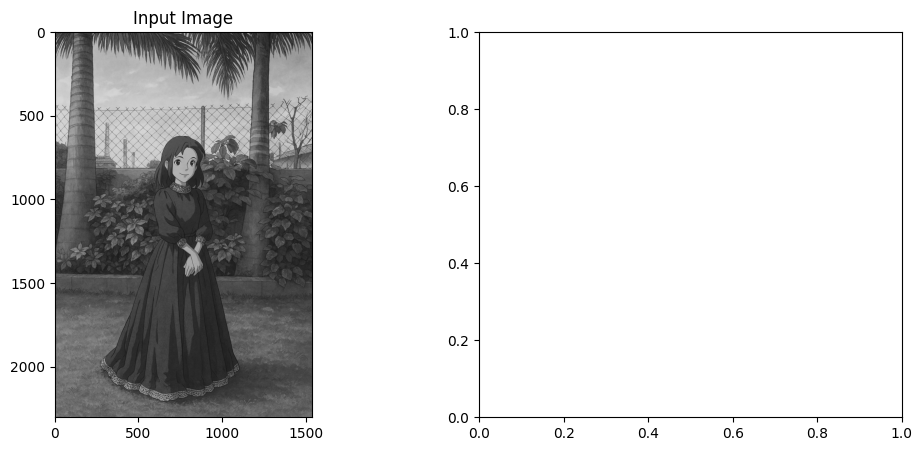

In [11]:
input_path = "/content/Avani.jpg"

input_image = cv2.imread(input_path)

gray_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)

input_hist = generate_histogram(gray_image)

intensity = np.arange(256)

plt.figure(figsize = (12,5))

plt.subplot(1,2,1)
plt.imshow(gray_image, cmap = "gray")
plt.title("Input Image")

plt.subplot(1,2,2)
plt.bar(intensity, input_hist, color = "r")
plt.title("Input Image Histogram")
plt.show()

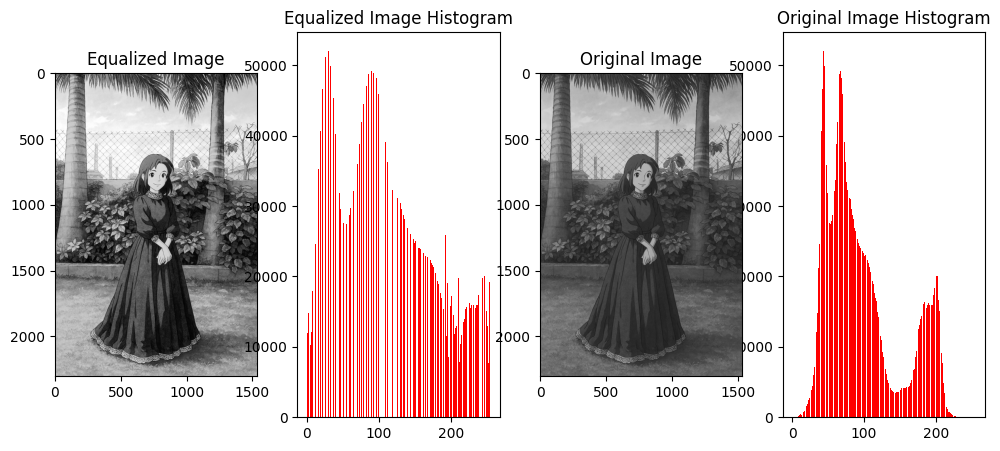

In [ ]:
# histogram Equalization

def perform_histogram_equalization(image):
  gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  equalized_image = cv2.equalizeHist(gray_image)
  return equalized_image

equalized_image = perform_histogram_equalization(input_image)

equalized_hist = generate_histogram(equalized_image)
original_hist = generate_histogram(gray_image)

plt.figure(figsize = (12,5))

plt.subplot(1,4,1)
plt.imshow(equalized_image, cmap = "gray")
plt.title("Equalized Image")

plt.subplot(1,4,2)
plt.bar(intensity, equalized_hist, color = "r")
plt.title("Equalized Image Histogram")

plt.subplot(1,4,4)
plt.bar(intensity, original_hist, color = "r")
plt.title("Original Image Histogram")

plt.subplot(1,4,3)
plt.imshow(gray_image, cmap = "gray")
plt.title("Original Image")
plt.show()

Text(0.5, 1.0, 'Original Image Histogram')

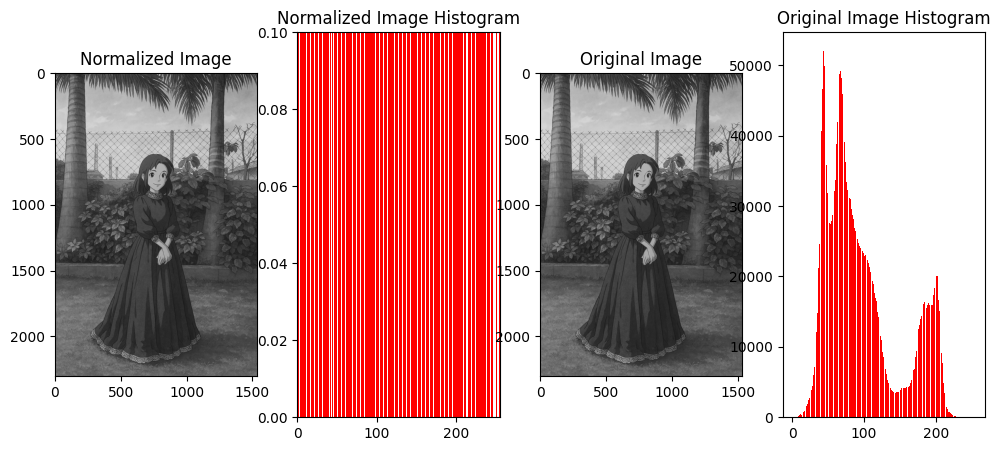

In [ ]:
def perform_hitogram_normalizaion(image):
  gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
  normalized_image = cv2.normalize(gray_image, None, 0, 255, cv2.NORM_MINMAX)
  return normalized_image

normalized_image = perform_hitogram_normalizaion(input_image)

normalized_hist = generate_histogram(normalized_image)

original_hist = generate_histogram(gray_image)

plt.figure(figsize = (12,5))

plt.subplot(1,4,1)
plt.imshow(normalized_image, cmap = "gray")
plt.title("Normalized Image")

plt.subplot(1,4,2)
plt.bar(intensity, normalized_hist, color = "r")
plt.title("Normalized Image Histogram")
plt.xlim([0, 255])
plt.ylim([0, 01])

plt.subplot(1,4,3)
plt.imshow(gray_image, cmap = "gray")
plt.title("Original Image")

plt.subplot(1,4,4)
plt.bar(intensity, original_hist, color = "r")
plt.title("Original Image Histogram")


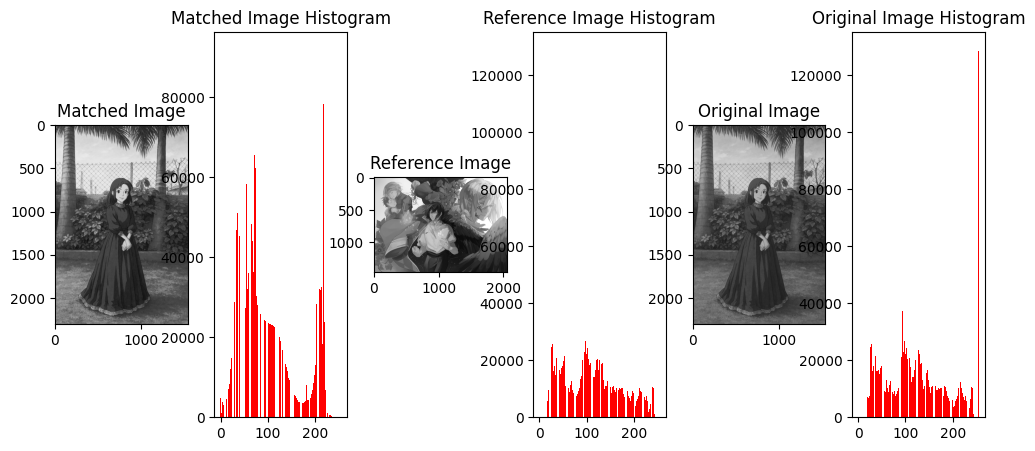

In [15]:
def perform_histogram_matching(input_image, reference_image):
  input_gray = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)
  reference_gray = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)

  input_hist = generate_histogram(input_gray)
  reference_hist = generate_histogram(reference_gray)

  input_cdf = input_hist.cumsum()
  reference_cdf = reference_hist.cumsum()

  input_cdf_normalized = input_cdf * input_gray.max() / input_cdf.max()
  reference_cdf_normalized = reference_cdf * reference_gray.max() / reference_cdf.max()

  input_cdf_normalized = np.ma.filled(input_cdf_normalized, 0).astype('uint8')
  reference_cdf_normalized = np.ma.filled(reference_cdf_normalized, 0).astype('uint8')

  matched_image = cv2.LUT(input_gray, reference_cdf_normalized)

  return matched_image
input_path2 = "/content/786016.png"
reference_image = cv2.imread(input_path2)
matched_image = perform_histogram_matching(input_image, reference_image)
matched_hist = generate_histogram(matched_image)
original_image = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)
reference_gray = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)
reference_hist = generate_histogram(reference_gray)
original_hist = generate_histogram(reference_gray)
intensity = np.arange(256)
matched_hist = np.ravel(matched_hist)
original_hist = np.ravel(original_hist)
reference_hist = np.ravel(reference_hist)

plt.figure(figsize = (12,5))
plt.subplot(1,6,1)
plt.imshow(matched_image, cmap = "gray")
plt.title("Matched Image")

plt.subplot(1,6,2)
plt.bar(intensity, matched_hist, color = "r")
plt.title("Matched Image Histogram")

plt.subplot(1,6,3)
plt.imshow(reference_gray, cmap = "gray")
plt.title("Reference Image")

plt.subplot(1,6,4)
plt.bar(intensity, reference_hist, color = "r")
plt.title("Reference Image Histogram")

plt.subplot(1,6,5)
plt.imshow(original_image, cmap = "gray")
plt.title("Original Image")

plt.subplot(1,6,6)
plt.bar(intensity, original_hist, color = "r")
plt.title("Original Image Histogram")

plt.show()

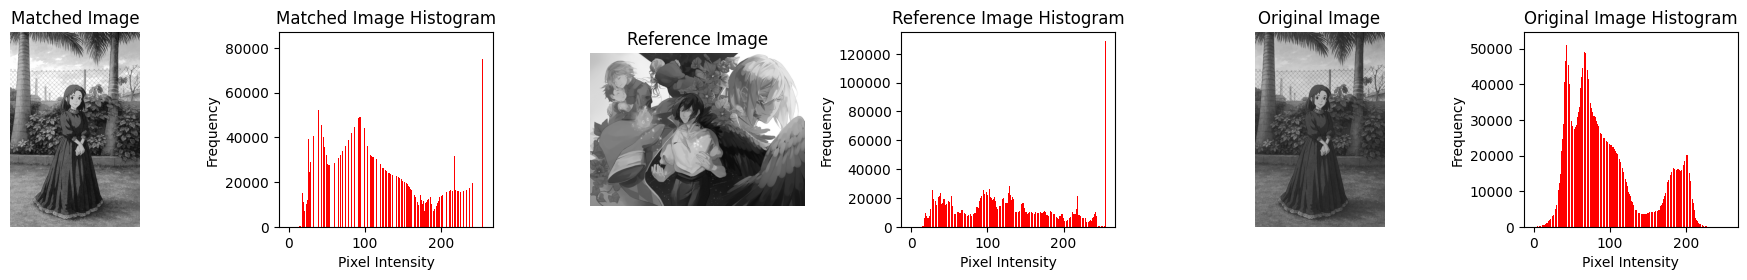

In [17]:
import cv2
import numpy as np
import matplotlib.pyplot as plt



def generate_histogram(image):
    hist = cv2.calcHist([image], [0], None, [256], [0, 256])
    return hist.flatten()



def perform_histogram_matching(input_image, reference_image):

    input_gray = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)
    reference_gray = cv2.cvtColor(reference_image, cv2.COLOR_BGR2GRAY)


    input_hist = generate_histogram(input_gray)
    reference_hist = generate_histogram(reference_gray)

    input_cdf = input_hist.cumsum()
    reference_cdf = reference_hist.cumsum()

    input_cdf = input_cdf / input_cdf[-1]
    reference_cdf = reference_cdf / reference_cdf[-1]

    lookup_table = np.zeros(256, dtype=np.uint8)

    for i in range(256):

        j = np.argmin(np.abs(reference_cdf - input_cdf[i]))

        lookup_table[i] = j

    matched_image = cv2.LUT(input_gray, lookup_table)

    return matched_image



input_path = "/content/Avani.jpg"


reference_path = "/content/786016.png"

input_image = cv2.imread(input_path)
reference_image = cv2.imread(reference_path)


if input_image is None:
    raise ValueError("Input image could not be loaded. Check the input path.")

if reference_image is None:
    raise ValueError("Reference image could not be loaded. Check the reference path.")



matched_image = perform_histogram_matching(
    input_image,
    reference_image
)



original_image = cv2.cvtColor(
    input_image,
    cv2.COLOR_BGR2GRAY
)

reference_gray = cv2.cvtColor(
    reference_image,
    cv2.COLOR_BGR2GRAY
)



original_hist = generate_histogram(original_image)

reference_hist = generate_histogram(reference_gray)

matched_hist = generate_histogram(matched_image)

intensity = np.arange(256)


plt.figure(figsize=(18, 5))

plt.subplot(2, 6, 1)

plt.imshow(matched_image, cmap="gray")

plt.title("Matched Image")

plt.axis("off")

plt.subplot(2, 6, 2)

plt.bar(intensity, matched_hist, color="r")

plt.title("Matched Image Histogram")

plt.xlabel("Pixel Intensity")

plt.ylabel("Frequency")


plt.subplot(2, 6, 3)

plt.imshow(reference_gray, cmap="gray")

plt.title("Reference Image")

plt.axis("off")

plt.subplot(2, 6, 4)

plt.bar(intensity, reference_hist, color="r")

plt.title("Reference Image Histogram")

plt.xlabel("Pixel Intensity")

plt.ylabel("Frequency")


plt.subplot(2, 6, 5)

plt.imshow(original_image, cmap="gray")

plt.title("Original Image")

plt.axis("off")


plt.subplot(2, 6, 6)

plt.bar(intensity, original_hist, color="r")

plt.title("Original Image Histogram")

plt.xlabel("Pixel Intensity")

plt.ylabel("Frequency")


plt.tight_layout()

plt.show()